# Driver Drowsiness Detection: eye-state model + system evaluation
Works on **Google Colab** and **local Jupyter**. Run the cells top to bottom.
1. Setup and data, 2. EDA, 3. Subject-wise split, 4. Train CNN, 5. Evaluate (accuracy, recall, AUC), 6. System test on video clips (system success rate).

**Colab:** Runtime → Change runtime type → GPU (optional, speeds up training).

**Run order (local Jupyter):** 1) `pip` cell and imports, 2) Section 1 (set `DATA_DIR`), 3) Sections 2 to 5 (trains and saves `eye_state_model.keras`), 4) Section 8 (live camera). Sections 6 and 7 are optional tests.

In [ ]:
import sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow', 'scikit-learn', 'pillow', 'tqdm',
                'pandas', 'seaborn', 'opencv-python-headless', 'mediapipe==0.10.14'])
print('Colab' if IN_COLAB else 'Local Jupyter')

Colab


In [ ]:
import os, glob, random, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve)
SEED = 42; random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
IMG = 64
print('TF', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))

## 1. Get the data

Use one copy of the **MRL Eye Dataset**. Set `DATA_DIR` to the folder containing the eye images (searched recursively).

- **Colab:** upload the dataset ZIP when prompted, or mount Drive and set `DATA_DIR`.
- **Local Jupyter:** set `DATA_DIR` to your dataset folder.

MRL filenames contain these fields in order: subject ID, image ID, gender, glasses, **eye state**, reflections, lighting, and sensor ID. The official labels are **0 = closed** and **1 = open**. We convert these to our model labels as **1 = closed** and **0 = open**, so the model's sigmoid output represents the probability that an eye is closed. The subject ID is used to keep people in the test set separate from people in training.

In [ ]:
DATA_DIR   = '/content/mrl' if IN_COLAB else './mrl'   # <- LOCAL: put the MRL images (any subfolders) in ./mrl, or change this path
KAGGLE_SLUG = ''                     # e.g. 'owner/mrl-eye-dataset' (Option A); leave '' to skip
MAX_IMAGES = 40000                   # cap for RAM/time; set None for everything

if IN_COLAB and KAGGLE_SLUG:
    from google.colab import files
    print('Upload kaggle.json'); files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    os.system('mv kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json && pip install -q kaggle')
    os.system(f'kaggle datasets download -d {KAGGLE_SLUG} -p /content/dl --unzip')
    DATA_DIR = '/content/dl'
elif IN_COLAB and not os.path.exists(DATA_DIR):
    from google.colab import files
    print('Upload a .zip of the dataset'); up = files.upload()
    z = list(up)[0]; os.system(f'unzip -q "{z}" -d {DATA_DIR}')

paths = [p for ext in ('png','jpg','jpeg','bmp') for p in glob.glob(os.path.join(DATA_DIR, '**', f'*.{ext}'), recursive=True)]
print(len(paths), 'images found')
assert paths, 'No images found: check DATA_DIR'

Upload a .zip of the dataset


Saving mrlEyes_2018_01.zip to mrlEyes_2018_01.zip
84898 images found


In [ ]:
def parse(p):
    fields = os.path.basename(p).rsplit('.', 1)[0].split('_')

    # MRL: subject, image ID, gender, glasses, eye state, reflections, lighting, sensor
    if len(fields) >= 8 and fields[0].startswith('s') and fields[4] in ('0', '1'):
        subject_id = fields[0]
        closed_label = 1 if fields[4] == '0' else 0
        return subject_id, closed_label

    # Alternative folder-based dataset
    low = p.lower().replace(' ', '').replace('-', '').replace('_', '')
    if 'closed' in low:
        return None, 1
    if 'open' in low:
        return None, 0
    return None, None

meta = pd.DataFrame([(p,) + parse(p) for p in paths],
                    columns=['path', 'subject', 'closed']).dropna(subset=['closed'])
meta['closed'] = meta['closed'].astype(int)

HAS_SUBJECTS = meta.subject.notna().all()
if not HAS_SUBJECTS:
    print('WARNING: subject IDs not found. Using a stratified random split.')
    meta['subject'] = 'unknown'

if MAX_IMAGES and len(meta) > MAX_IMAGES:
    meta = meta.sample(MAX_IMAGES, random_state=SEED).reset_index(drop=True)

print('Label counts (0 = open, 1 = closed):')
print(meta['closed'].value_counts().sort_index().rename({0: 'open', 1: 'closed'}))
print('Subjects:', meta.subject.nunique())
assert meta['closed'].nunique() == 2, 'Both open and closed labels must be present.'

Label counts (0 = open, 1 = closed):
closed
open      20273
closed    19727
Name: count, dtype: int64
Subjects: 37


## 2. Quick EDA

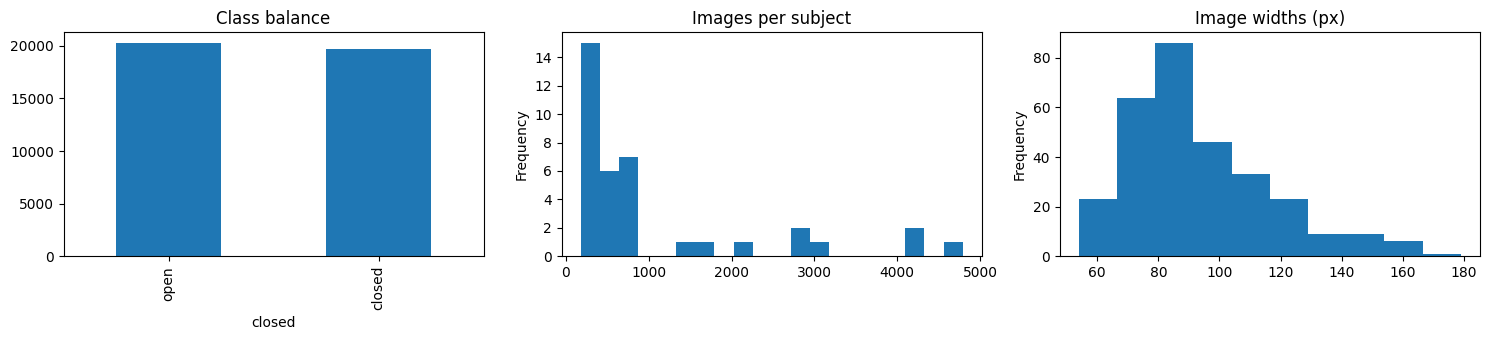

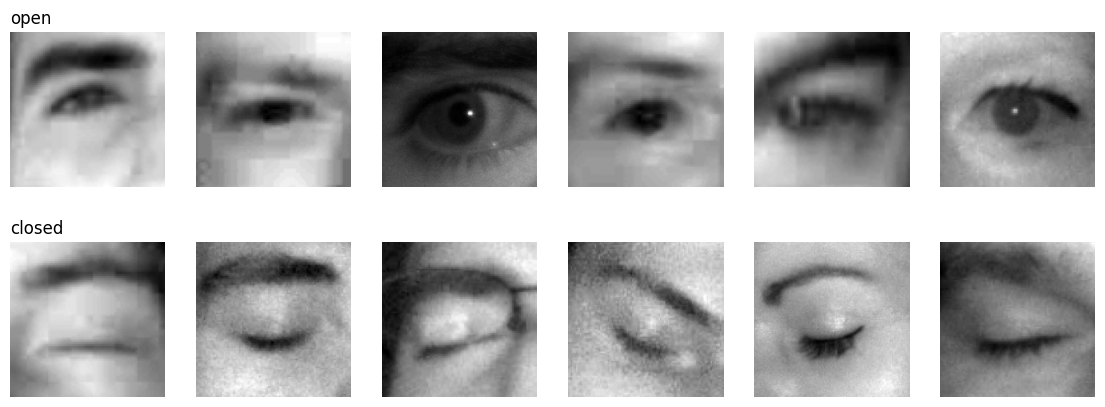

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
meta.closed.map({0:'open',1:'closed'}).value_counts().plot.bar(ax=ax[0], title='Class balance')
if HAS_SUBJECTS: meta.groupby('subject').size().plot.hist(bins=20, ax=ax[1], title='Images per subject')
sizes = [Image.open(p).size for p in meta.path.sample(min(300,len(meta)), random_state=0)]
pd.Series([s[0] for s in sizes]).plot.hist(ax=ax[2], title='Image widths (px)'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for r, lab in enumerate([0,1]):
    for c, p in enumerate(meta[meta.closed==lab].path.sample(6, random_state=1)):
        ax[r,c].imshow(Image.open(p).convert('L'), cmap='gray'); ax[r,c].axis('off')
    ax[r,0].set_title('open' if lab==0 else 'closed', loc='left')
plt.show()

## 3. Load images and split (subject-wise when possible)

In [ ]:
def load(paths):
    return np.array([np.array(Image.open(p).convert('L').resize((IMG,IMG)), dtype=np.uint8) for p in tqdm(paths)])[...,None]
X = load(meta.path); y = meta.closed.values; g = meta.subject.values

if HAS_SUBJECTS:
    tr, rest = next(GroupShuffleSplit(1, test_size=0.30, random_state=SEED).split(X, y, g))
    v, t = next(GroupShuffleSplit(1, test_size=0.5, random_state=SEED).split(X[rest], y[rest], g[rest]))
    va, te = rest[v], rest[t]
    assert not (set(g[tr]) & set(g[te])) and not (set(g[va]) & set(g[te])), 'subject leakage'
else:
    idx = np.arange(len(y)); tr, rest = train_test_split(idx, test_size=0.3, stratify=y, random_state=SEED)
    va, te = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=SEED)
print('train/val/test:', len(tr), len(va), len(te))

  0%|          | 0/40000 [00:00<?, ?it/s]

train/val/test: 26195 10932 2873


## 4. Train the eye-state prediction model

This CNN learns visual patterns from eye images. Its output is the probability that an eye is **closed**. We use a subject-wise validation set and save the best model.

Training class weights: {0: np.float64(0.9663912048992843), 1: np.float64(1.036030691346306)}
Epoch 1/25
410/410 ━━━━━━━━━━━━━━━━━━━━ 417s 1s/step - accuracy: 0.8902 - auc: 0.9617 - loss: 0.2630 - precision: 0.8582 - recall: 0.9254 - val_accuracy: 0.5107 - val_auc: 0.5048 - val_loss: 5.9893 - val_precision: 0.5107 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 2/25
410/410 ━━━━━━━━━━━━━━━━━━━━ 442s 1s/step - accuracy: 0.9708 - auc: 0.9957 - loss: 0.0829 - precision: 0.9684 - recall: 0.9711 - val_accuracy: 0.9150 - val_auc: 0.9684 - val_loss: 0.2561 - val_precision: 0.8814 - val_recall: 0.9633 - learning_rate: 3.0000e-04
Epoch 3/25
410/410 ━━━━━━━━━━━━━━━━━━━━ 412s 1s/step - accuracy: 0.9807 - auc: 0.9975 - loss: 0.0575 - precision: 0.9798 - recall: 0.9801 - val_accuracy: 0.9469 - val_auc: 0.9861 - val_loss: 0.1435 - val_precision: 0.9521 - val_recall: 0.9434 - learning_rate: 3.0000e-04
Epoch 4/25
410/410 ━━━━━━━━━━━━━━━━━━━━ 407s 992ms/step - accuracy: 0.9837 - auc: 0.9984 - lo

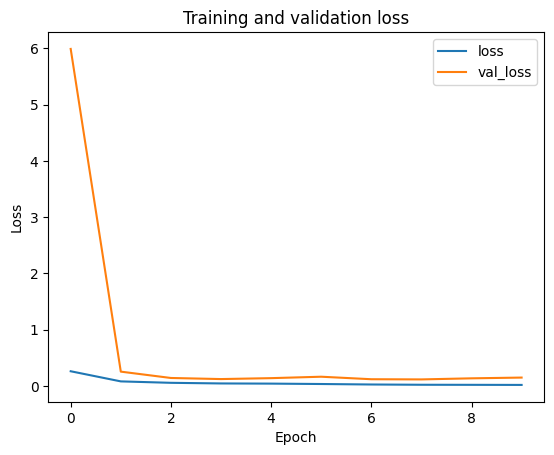

In [ ]:
L = tf.keras.layers

def build_model():
    return tf.keras.Sequential([
        L.Input(shape=(IMG, IMG, 1)),
        L.Rescaling(1./255),

        L.Conv2D(32, 3, padding='same', activation='relu'),
        L.BatchNormalization(),
        L.MaxPooling2D(),

        L.Conv2D(64, 3, padding='same', activation='relu'),
        L.BatchNormalization(),
        L.MaxPooling2D(),

        L.Conv2D(128, 3, padding='same', activation='relu'),
        L.BatchNormalization(),
        L.MaxPooling2D(),

        L.Conv2D(128, 3, padding='same', activation='relu'),
        L.BatchNormalization(),
        L.GlobalAveragePooling2D(),

        L.Dropout(0.4),
        L.Dense(128, activation='relu'),
        L.Dropout(0.3),
        L.Dense(1, activation='sigmoid')
    ])

model = build_model()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

# Calculate weights from the training labels only.
counts = np.bincount(y[tr], minlength=2)
class_weights = {
    0: len(tr) / (2 * max(counts[0], 1)),
    1: len(tr) / (2 * max(counts[1], 1))
}
print('Training class weights:', class_weights)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc', mode='max', patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', patience=2, factor=0.5, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'eye_state_model.keras', monitor='val_auc',
        mode='max', save_best_only=True
    )
]

history = model.fit(
    X[tr], y[tr],
    validation_data=(X[va], y[va]),
    epochs=25,
    batch_size=64,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

model = tf.keras.models.load_model('eye_state_model.keras')

pd.DataFrame(history.history)[['loss', 'val_loss']].plot(
    title='Training and validation loss'
)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

## 5. Evaluation on the held-out test set

Chosen threshold from validation data: 0.83
Best validation F1 for closed eyes: 0.9695
accuracy            0.9492
precision_closed    0.9569
recall_closed       0.9454
f1_closed           0.9511
auc                 0.9925
Actual test labels: {0: 1371, 1: 1502} (0=open, 1=closed)
Predicted test labels: {0: 1389, 1: 1484} (0=open, 1=closed)


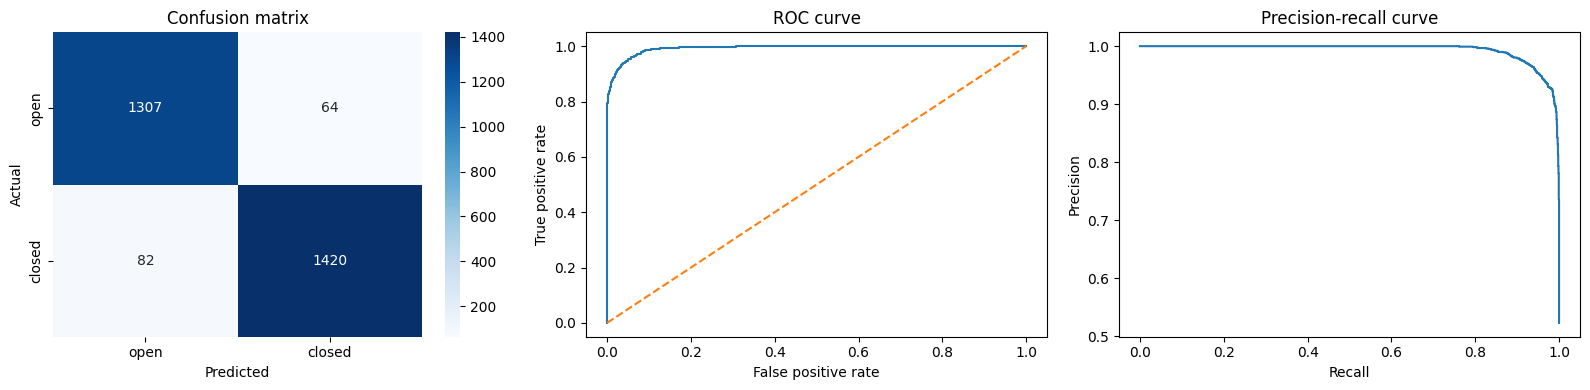

Per-subject accuracy: min 0.791 | median 0.944 | max 1.000
Saved threshold: 0.8299999999999996
Saved model: eye_state_model.keras


In [ ]:
# First choose a decision threshold using validation data only.
val_prob = model.predict(X[va], batch_size=256, verbose=0).ravel()
val_true = y[va]

thresholds = np.arange(0.10, 0.91, 0.01)
val_f1 = [f1_score(val_true, (val_prob >= t).astype(int), zero_division=0)
          for t in thresholds]
BEST_THRESHOLD = float(thresholds[int(np.argmax(val_f1))])
THR = BEST_THRESHOLD

print(f'Chosen threshold from validation data: {BEST_THRESHOLD:.2f}')
print(f'Best validation F1 for closed eyes: {max(val_f1):.4f}')

# Evaluate once on the untouched test set.
p = model.predict(X[te], batch_size=256, verbose=0).ravel()
yt = y[te]
yh = (p >= BEST_THRESHOLD).astype(int)

results = {
    'accuracy': accuracy_score(yt, yh),
    'precision_closed': precision_score(yt, yh, zero_division=0),
    'recall_closed': recall_score(yt, yh, zero_division=0),
    'f1_closed': f1_score(yt, yh, zero_division=0),
    'auc': roc_auc_score(yt, p)
}
print(pd.Series(results).round(4).to_string())

print('Actual test labels:', pd.Series(yt).value_counts().sort_index().to_dict(),
      '(0=open, 1=closed)')
print('Predicted test labels:', pd.Series(yh).value_counts().sort_index().to_dict(),
      '(0=open, 1=closed)')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.heatmap(
    confusion_matrix(yt, yh, labels=[0, 1]), annot=True, fmt='d',
    cmap='Blues', ax=ax[0],
    xticklabels=['open', 'closed'], yticklabels=['open', 'closed']
)
ax[0].set(xlabel='Predicted', ylabel='Actual', title='Confusion matrix')

fpr, tpr, _ = roc_curve(yt, p)
ax[1].plot(fpr, tpr)
ax[1].plot([0, 1], [0, 1], '--')
ax[1].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate')

precision, recall, _ = precision_recall_curve(yt, p)
ax[2].plot(recall, precision)
ax[2].set(title='Precision-recall curve', xlabel='Recall', ylabel='Precision')

plt.tight_layout()
plt.show()

if HAS_SUBJECTS:
    per_subject = pd.DataFrame({'subject': g[te], 'correct': yh == yt})
    per_subject = per_subject.groupby('subject').correct.mean()
    print('Per-subject accuracy: min %.3f | median %.3f | max %.3f' %
          (per_subject.min(), per_subject.median(), per_subject.max()))

model.save('eye_state_model.keras')
import json
json.dump({'threshold': BEST_THRESHOLD}, open('eye_state_model_threshold.json', 'w'))
print('Saved threshold:', BEST_THRESHOLD)
print('Saved model: eye_state_model.keras')

## 6. Predict the state of a new eye image
Set `IMAGE_PATH` to an eye image. The model returns **open** or **closed** and its estimated closed-eye probability. This predicts eye state, not driver fatigue by itself.

In [ ]:
def predict_eye(image_path):
    image = Image.open(image_path).convert('L').resize((IMG, IMG))
    array = np.array(image, dtype=np.uint8)[None, ..., None]

    closed_probability = float(model.predict(array, verbose=0)[0][0])
    prediction = 'CLOSED' if closed_probability >= BEST_THRESHOLD else 'OPEN'

    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.title(
        f'Prediction: {prediction} | Closed-eye probability: {closed_probability:.1%}'
    )
    plt.show()

    return prediction, closed_probability

# Example:
# predict_eye('/content/sample_eye.png')


## 7. (Optional) System test: system success rate on video clips
**Skip this section if you have no test clips.** Section 8 does not depend on it.
Put short clips (10-30 s, face visible, frontal) in two folders:
```
clips/drowsy/*.mp4    (eyes closing >1 s, repeated long closures, yawning)
clips/alert/*.mp4     (normal blinking, talking, looking around)
```
On Colab, upload and unzip a `clips.zip`; locally, just point `CLIPS_DIR` at the folder. Record at least 20 clips per class, ideally from 2-3 people. Acted drowsiness is a functional test, not proof of real-world fatigue detection.

In [ ]:
import sys, os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
import cv2

import mediapipe as mp
mp_face_mesh = mp.solutions.face_mesh

CLIPS_DIR = '/content/clips'
CLOSE_SEC, GAP_TOL, PERCLOS_WIN, PERCLOS_ON, STEP = 1.0, 0.2, 30.0, 0.20, 2
THR = BEST_THRESHOLD
L_EYE=[362,385,387,263,373,380]; R_EYE=[33,160,158,133,153,144]

def crop(gray, lm, ids, w, h):
    pts = np.array([[lm[i].x*w, lm[i].y*h] for i in ids]); x0,y0 = pts.min(0); x1,y1 = pts.max(0)
    cx, cy, s = (x0+x1)/2, (y0+y1)/2, max(x1-x0,1)*1.5
    c = gray[max(int(cy-s/2),0):int(cy+s/2), max(int(cx-s/2),0):int(cx+s/2)]
    return None if c.size==0 else cv2.resize(c,(IMG,IMG))

def run_clip(path, fm):
    cap = cv2.VideoCapture(path); fps = cap.get(cv2.CAP_PROP_FPS) or 30
    i, hist, cs, cl, alert_t = 0, [], None, None, None
    while True:
        ok, fr = cap.read()
        if not ok: break
        i += 1
        if i % STEP: continue
        t = i/fps; h,w = fr.shape[:2]
        r = fm.process(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        if not r.multi_face_landmarks: continue
        lm = r.multi_face_landmarks[0].landmark; gr = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
        crops = [crop(gr, lm, ids, w, h) for ids in (L_EYE,R_EYE)]
        if any(c is None for c in crops): continue
        closed = float(model.predict(np.array(crops)[...,None], verbose=0).mean()) > THR
        hist = [(a,b) for a,b in hist+[(t,closed)] if t-a <= PERCLOS_WIN]
        if closed: cs = t if cs is None else cs; cl = t
        elif cs is not None and t-cl > GAP_TOL: cs = None
        long_close = cs is not None and (cl-cs) >= CLOSE_SEC
        perclos = np.mean([b for _,b in hist]) if hist[-1][0]-hist[0][0] >= 0.5*PERCLOS_WIN else 0
        if (long_close or perclos > PERCLOS_ON) and alert_t is None: alert_t = t
    cap.release(); return alert_t

if IN_COLAB and not os.path.exists(CLIPS_DIR):
    from google.colab import files
    print('Upload clips.zip'); up = files.upload(); os.system(f'unzip -q "{list(up)[0]}" -d {CLIPS_DIR}')
fm = mp_face_mesh.FaceMesh(max_num_faces=1)
rows = []
for lab in ('drowsy','alert'):
    for f in tqdm(sorted(glob.glob(f'{CLIPS_DIR}/**/{lab}/*.*', recursive=True)), desc=lab):
        a = run_clip(f, fm); rows.append(dict(clip=f, truth=lab, pred='drowsy' if a is not None else 'alert', delay_s=a))
out = pd.DataFrame(rows); out.to_csv('system_results.csv', index=False)
assert len(out), 'No clips found: expected clips/drowsy/* and clips/alert/*'
tp=((out.truth=='drowsy')&(out.pred=='drowsy')).sum(); fn=((out.truth=='drowsy')&(out.pred=='alert')).sum()
fp=((out.truth=='alert')&(out.pred=='drowsy')).sum(); tn=((out.truth=='alert')&(out.pred=='alert')).sum()
print(f'SYSTEM SUCCESS RATE: {(tp+tn)/len(out):.1%}  ({len(out)} clips)')
print(f'Drowsy detection rate: {tp/max(tp+fn,1):.1%} | False-alarm rate: {fp/max(fp+tn,1):.1%} | median delay: {out.delay_s.dropna().median():.2f}s')
sns.heatmap([[tn,fp],[fn,tp]], annot=True, fmt='d', cmap='Blues', xticklabels=['alert','drowsy'], yticklabels=['alert','drowsy'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('System confusion matrix'); plt.show()

ModuleNotFoundError: No module named 'mediapipe'

## 8. Live webcam drowsiness detection (local Jupyter only)
Needs a Jupyter server running **on your own computer** (address bar shows `localhost`). On Colab, Kaggle or any remote server the camera is not reachable.

- Run sections 1 to 5 first (this trains and saves the model), **or** just have `eye_state_model.keras` (and `eye_state_model_threshold.json`) in the notebook folder.
- Click the stop button (■) in the toolbar to end early. It also stops by itself after `RUN_SECONDS`.
- Alarm rule: eyes closed continuously for `CLOSE_SEC` seconds, **or** PERCLOS above `PERCLOS_ON` over the last `PERCLOS_WIN` seconds.

In [ ]:
import os, json, time, sys
from collections import deque
import numpy as np, cv2, tensorflow as tf
import mediapipe as mp
from IPython.display import display, Image as IPImage

# ---------------- settings ----------------
CAMERA_INDEX = 0
RUN_SECONDS  = 120
CLOSE_SEC, GAP_TOL, PERCLOS_WIN, PERCLOS_ON = 1.0, 0.2, 30.0, 0.20
IMG_SIZE = 64
LIVE_L_EYE = [362, 385, 387, 263, 373, 380]
LIVE_R_EYE = [33, 160, 158, 133, 153, 144]

class DrowsinessLogic:
    def __init__(self, close_sec=1.0, gap_tol=0.2, perclos_win=30.0, perclos_on=0.20, min_fill=0.5):
        self.close_sec, self.gap_tol = close_sec, gap_tol
        self.perclos_win, self.perclos_on, self.min_fill = perclos_win, perclos_on, min_fill
        self.hist, self.close_start, self.last_closed = deque(), None, None
    def reset_closure(self):
        self.close_start = self.last_closed = None
    def update(self, t, closed):
        self.hist.append((t, closed))
        while self.hist and t - self.hist[0][0] > self.perclos_win: self.hist.popleft()
        if closed:
            if self.close_start is None: self.close_start = t
            self.last_closed = t
        elif self.close_start is not None and t - self.last_closed > self.gap_tol:
            self.close_start = None
        dur = (self.last_closed - self.close_start) if self.close_start is not None else 0.0
        span = self.hist[-1][0] - self.hist[0][0]
        perclos = sum(c for _, c in self.hist) / len(self.hist) if span >= self.min_fill * self.perclos_win else 0.0
        if dur >= self.close_sec or perclos > self.perclos_on: state = 'DROWSY'
        elif closed: state = 'EYES CLOSED'
        else: state = 'ALERT'
        return state, dur, perclos

def live_crop(gray, lm, ids, w, h):
    pts = np.array([[lm[i].x * w, lm[i].y * h] for i in ids])
    x0, y0 = pts.min(0); x1, y1 = pts.max(0)
    cx, cy, s = (x0 + x1) / 2, (y0 + y1) / 2, max(x1 - x0, 1) * 1.5
    c = gray[max(int(cy - s / 2), 0):int(cy + s / 2), max(int(cx - s / 2), 0):int(cx + s / 2)]
    return None if c.size == 0 else cv2.resize(c, (IMG_SIZE, IMG_SIZE))

def run_live():
    if 'google.colab' in sys.modules:
        print('Colab cannot access your camera through OpenCV. Run this notebook on local Jupyter.'); return
    # model + threshold: use the ones in memory, else load from disk
    live_model = globals().get('model') or tf.keras.models.load_model('eye_state_model.keras')
    if 'BEST_THRESHOLD' in globals(): thr = BEST_THRESHOLD
    elif os.path.exists('eye_state_model_threshold.json'): thr = json.load(open('eye_state_model_threshold.json'))['threshold']
    else: thr = 0.5
    print(f'Using closed-eye threshold {thr:.2f}')

    cap = cv2.VideoCapture(CAMERA_INDEX)
    if not cap.isOpened():
        print('Cannot open the camera. Close other apps using it, or try CAMERA_INDEX = 1.'); return
    fm = mp.solutions.face_mesh.FaceMesh(max_num_faces=1, refine_landmarks=True,
                                         min_detection_confidence=0.5, min_tracking_confidence=0.5)
    logic = DrowsinessLogic(CLOSE_SEC, GAP_TOL, PERCLOS_WIN, PERCLOS_ON)
    handle = display(display_id=True)
    t0, p_closed = time.time(), 0.0
    try:
        while time.time() - t0 < RUN_SECONDS:
            ok, fr = cap.read()
            if not ok: break
            h, w = fr.shape[:2]; t = time.time()
            res = fm.process(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
            state, dur, perclos = 'NO FACE', 0.0, 0.0
            if res.multi_face_landmarks:
                lm = res.multi_face_landmarks[0].landmark
                gray = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
                crops = [live_crop(gray, lm, ids, w, h) for ids in (LIVE_L_EYE, LIVE_R_EYE)]
                if all(c is not None for c in crops):
                    batch = np.array(crops, dtype=np.uint8)[..., None]
                    p_closed = float(live_model(batch, training=False).numpy().mean())
                    state, dur, perclos = logic.update(t, p_closed >= thr)
            else:
                logic.reset_closure()
            color = (0, 0, 255) if state == 'DROWSY' else (0, 165, 255) if state == 'EYES CLOSED' else (0, 200, 0)
            if state == 'DROWSY': cv2.rectangle(fr, (0, 0), (w - 1, h - 1), (0, 0, 255), 10)
            cv2.putText(fr, state, (20, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.2, color, 3)
            cv2.putText(fr, f'P(closed)={p_closed:.2f}  closed {dur:.1f}s  PERCLOS {perclos:.0%}',
                        (20, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
            small = cv2.resize(fr, (640, int(640 * h / w)))
            handle.update(IPImage(data=cv2.imencode('.jpg', small)[1].tobytes()))
    except KeyboardInterrupt:
        print('Stopped.')
    finally:
        cap.release(); fm.close()

run_live()
